# TSP Optimization with Simulated Annealing and Genetic Algorithms — Assignment Notebook

Works in **Jupyter** and **Google Colab**.

## Overview
You will solve the same TSP instance using **two heuristic optimization methods**:

1. **Simulated Annealing (SA)** with a 2-opt neighborhood  
2. **Genetic Algorithm (GA)** on **permutation tours** (a standard evolutionary approach for TSP)

The notebook provides:
- A reproducible TSP instance generator
- Tour utilities (length, validity)
- A 2-opt neighborhood operator
- Visualization helpers (tour plot + history plot)
- Baseline heuristic: nearest neighbor

## Tasks
### Task A — Simulated Annealing (SA)
Implement `simulated_annealing_tsp(...)`. Find sections with "TODO" to complete the implementations.

### Task B — Genetic Algorithm (GA)
Implement `genetic_algorithm_tsp(...)` plus helper functions:
- Tournament selection
- Order crossover (OX)
- Swap mutation
Find sections with "TODO" to complete the implementations.

## Deliverables
- Completed notebook (or exported `.py`) (find all TODOs and implement them)
- Write a technical report that includes:
  - Descriptions of the problem context, solutions (include important code snippets)
  - Experimental results, present the graphs, plots and data generated from the notebook based on your implementation.
    - SA parameters + best tour length
    - GA parameters + best tour length
    - Brief comparison: which worked better and why
    - More specifics can be found Part 6 below.
    - Optional work done in Part 7 below
  - Analysis of the experimental results.


---


In [1]:
# If running in a fresh environment, uncomment as needed:
# !pip -q install matplotlib

import math
import random
from dataclasses import dataclass
from typing import List, Tuple

import matplotlib.pyplot as plt


## Part 1 — TSP utilities (provided)

In [2]:
Point = Tuple[float, float]
Tour = List[int]

def make_cities(n: int = 40, seed: int = 7) -> List[Point]:
    # Reproducible 2D city coordinates in [0, 1]x[0, 1].
    rng = random.Random(seed)
    return [(rng.random(), rng.random()) for _ in range(n)]

def dist(a: Point, b: Point) -> float:
    dx = a[0] - b[0]
    dy = a[1] - b[1]
    return math.hypot(dx, dy)

def tour_length(cities: List[Point], tour: Tour) -> float:
    # Total length of a closed tour.
    n = len(tour)
    total = 0.0
    for i in range(n):
        total += dist(cities[tour[i]], cities[tour[(i + 1) % n]])
    return total

def is_valid_tour(tour: Tour, n: int) -> bool:
    return len(tour) == n and set(tour) == set(range(n))

def random_tour(n: int, rng: random.Random) -> Tour:
    t = list(range(n))
    rng.shuffle(t)
    return t

def nearest_neighbor_tour(cities: List[Point], start: int = 0) -> Tour:
    # Deterministic baseline: greedy nearest neighbor.
    n = len(cities)
    unvisited = set(range(n))
    tour = [start]
    unvisited.remove(start)
    cur = start
    while unvisited:
        nxt = min(unvisited, key=lambda j: dist(cities[cur], cities[j]))
        tour.append(nxt)
        unvisited.remove(nxt)
        cur = nxt
    return tour


## Part 2 — Neighborhood operator (2-opt) (provided)

In [3]:
def two_opt_swap(tour: Tour, i: int, k: int) -> Tour:
    # Return a new tour where the segment [i:k] is reversed.
    return tour[:i] + list(reversed(tour[i:k + 1])) + tour[k + 1:]

def random_two_opt_neighbor(tour: Tour, rng: random.Random) -> Tour:
    # Pick a random 2-opt move.
    n = len(tour)
    i = rng.randrange(0, n - 1)
    k = rng.randrange(i + 1, n)
    return two_opt_swap(tour, i, k)


## Part 3 — Visualization helpers (provided)

* You are encouraged to implement more variations of visualization.

In [4]:
def plot_tour(cities: List[Point], tour: Tour, title: str = "") -> None:
    xs = [cities[i][0] for i in tour] + [cities[tour[0]][0]]
    ys = [cities[i][1] for i in tour] + [cities[tour[0]][1]]

    plt.figure(figsize=(6, 6))
    plt.plot(xs, ys, marker="o")
    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.gca().set_aspect("equal", adjustable="box")
    plt.show()

def plot_history(series: List[float], title: str, ylabel: str = "Value") -> None:
    plt.figure(figsize=(7, 4))
    plt.plot(series)
    plt.title(title)
    plt.xlabel("Iteration")
    plt.ylabel(ylabel)
    plt.show()

def plot_compare(sa_hist: List[float], ga_hist: List[float]) -> None:
    # Overlay histories (x-axis is not identical meaning; this is a visual comparison).
    plt.figure(figsize=(8, 4))
    plt.plot(sa_hist, label="SA best-so-far")
    plt.plot([i * (len(sa_hist) / max(1, len(ga_hist)-1)) for i in range(len(ga_hist))], ga_hist, label="GA best-by-gen")
    plt.title("SA vs GA: Best tour length over time (scaled x-axis)")
    plt.xlabel("Progress (scaled)")
    plt.ylabel("Length")
    plt.legend()
    plt.show()


## Part 4 — Baseline tour (nearest neighbor) (provided)

Nearest-neighbor length: 6.0214


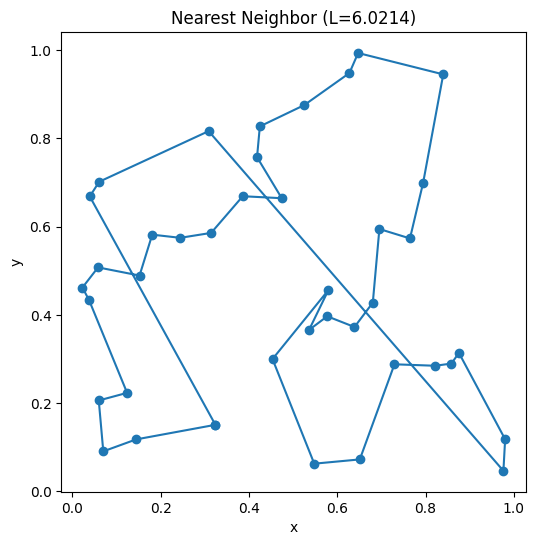

In [5]:
cities = make_cities(n=40, seed=7)

nn_tour = nearest_neighbor_tour(cities, start=0)
nn_len = tour_length(cities, nn_tour)
print(f"Nearest-neighbor length: {nn_len:.4f}")

plot_tour(cities, nn_tour, title=f"Nearest Neighbor (L={nn_len:.4f})")


# Part 5A — Code Skeleton: Simulated Annealing (SA)

Complete `simulated_annealing_tsp(...)`.

### SA acceptance rule
Let `delta = cand_len - cur_len`.
- If `delta <= 0`, accept.
- Else accept with probability `exp(-delta / T)`.

### Cooling schedule
Geometric cooling:
- `T = T * alpha` each iteration
- clamp `T = max(T, 1e-12)`


In [6]:
@dataclass
class SAConfig:
    iters: int = 20_000
    t0: float = 0.2
    alpha: float = 0.9995
    seed: int = 123
    report_every: int = 2000

def simulated_annealing_tsp(cities: List[Point], init_tour: Tour, cfg: SAConfig) -> Tuple[Tour, float, List[float]]:
    rng = random.Random(cfg.seed)
    n = len(cities)
    assert is_valid_tour(init_tour, n), "init_tour must be a valid permutation"
    assert cfg.t0 > 0 and 0 < cfg.alpha <= 1
    cur_tour = init_tour[:]
    cur_len = tour_length(cities, cur_tour)
    best_tour, best_len = cur_tour[:], cur_len
    history = [best_len]
    T = cfg.t0
    accepted_deltas, rejected_deltas = [], []
    uphill_accepted = 0
    current_history = [cur_len]
    for it in range(cfg.iters):
        cand_tour = random_two_opt_neighbor(cur_tour, rng)
        cand_len = tour_length(cities, cand_tour)
        delta = cand_len - cur_len
        accept = delta <= 0 or rng.random() < math.exp(-delta / T)
        if accept:
            accepted_deltas.append(delta)
            if delta > 1e-12:
                uphill_accepted += 1
            cur_tour, cur_len = cand_tour, cand_len
        else:
            rejected_deltas.append(delta)
        if cur_len < best_len:
            best_tour, best_len = cur_tour[:], cur_len
        history.append(best_len)
        current_history.append(cur_len)
        T = max(T * cfg.alpha, 1e-12)
        if cfg.report_every and (it + 1) % cfg.report_every == 0:
            print(f"[SA] iter={it+1:6d}  T={T:.4g}  cur={cur_len:.4f}  best={best_len:.4f}")
    # Diagnostics are stored separately so the professor's return signature stays unchanged.
    simulated_annealing_tsp.diagnostics = dict(
        accepted_deltas=accepted_deltas, rejected_deltas=rejected_deltas,
        uphill_accepted=uphill_accepted, current_history=current_history,
        evaluations=cfg.iters+1)
    return best_tour, best_len, history


## Run SA (after you implement it)

[SA] iter=  2000  T=0.07356  cur=8.3800  best=6.0214
[SA] iter=  4000  T=0.02705  cur=6.5972  best=6.0214


[SA] iter=  6000  T=0.00995  cur=5.3139  best=5.3139
[SA] iter=  8000  T=0.003659  cur=5.0057  best=5.0057
[SA] iter= 10000  T=0.001346  cur=5.0057  best=5.0057
[SA] iter= 12000  T=0.000495  cur=5.0057  best=5.0057
[SA] iter= 14000  T=0.0001821  cur=5.0057  best=5.0057
[SA] iter= 16000  T=6.696e-05  cur=5.0057  best=5.0057
[SA] iter= 18000  T=2.463e-05  cur=5.0057  best=5.0057
[SA] iter= 20000  T=9.057e-06  cur=5.0057  best=5.0057
SA best length: 5.0057
SA improvement vs NN: 16.87%


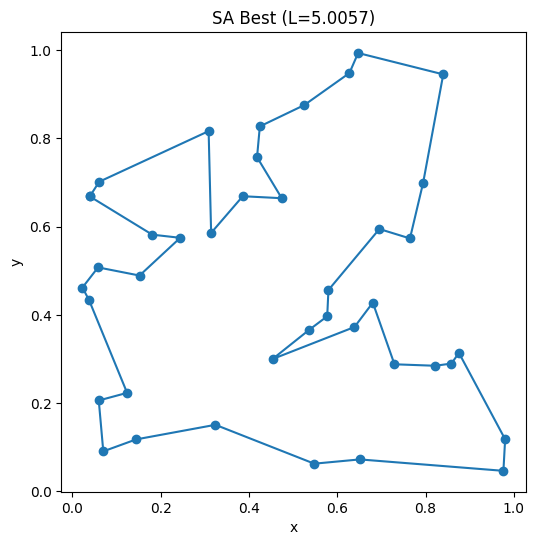

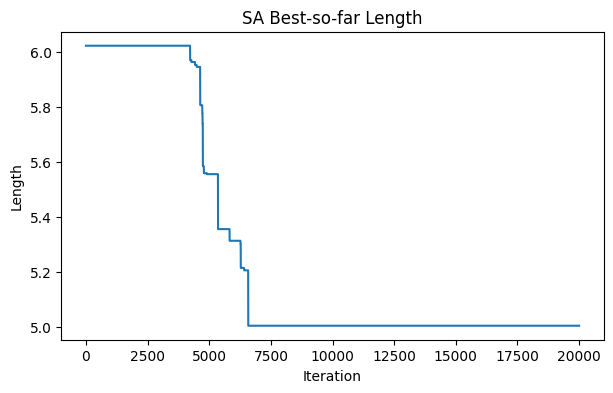

In [7]:
sa_cfg = SAConfig(iters=20_000, t0=0.2, alpha=0.9995, seed=123, report_every=2000)
sa_best_tour, sa_best_len, sa_hist = simulated_annealing_tsp(cities, nn_tour[:], sa_cfg)

print(f"SA best length: {sa_best_len:.4f}")
print(f"SA improvement vs NN: {(nn_len - sa_best_len) / nn_len * 100:.2f}%")

assert is_valid_tour(sa_best_tour, len(cities))

plot_tour(cities, sa_best_tour, title=f"SA Best (L={sa_best_len:.4f})")
plot_history(sa_hist, title="SA Best-so-far Length", ylabel="Length")


# Part 5B — Code Skeleton: Genetic Algorithm (GA) for TSP

Implement a GA that evolves a population of permutation tours.

You will implement:
- `tournament_select(...)`
- `order_crossover_ox(...)` (Order Crossover)
- `mutate_swap(...)`
- `genetic_algorithm_tsp(...)`


In [8]:
@dataclass
class GAConfig:
    pop_size: int = 200
    generations: int = 400
    tournament_k: int = 5
    crossover_rate: float = 0.9
    mutation_rate: float = 0.2
    elite_size: int = 5
    seed: int = 999
    report_every: int = 50

def tournament_select(pop: List[Tour], lengths: List[float], k: int, rng: random.Random) -> Tour:
    # Sample k candidates and minimize their tour lengths.
    indices = rng.sample(range(len(pop)), k)
    return pop[min(indices, key=lambda i: lengths[i])][:]

def order_crossover_ox(parent1: Tour, parent2: Tour, rng: random.Random) -> Tour:
    # Copy a contiguous segment of parent1; fill remaining positions from parent2
    # in cyclic order, preserving the relative order of remaining cities.
    n = len(parent1)
    a, b = sorted(rng.sample(range(n), 2))
    child = [-1] * n
    child[a:b+1] = parent1[a:b+1]
    used = set(child[a:b+1])
    remaining = (parent2[(b+1+i) % n] for i in range(n))
    pos = (b+1) % n
    for city in remaining:
        if city not in used:
            child[pos] = city
            pos = (pos+1) % n
    assert is_valid_tour(child, n)
    return child

def mutate_swap(tour: Tour, rng: random.Random) -> Tour:
    result = tour[:]
    i, j = rng.sample(range(len(result)), 2)
    result[i], result[j] = result[j], result[i]
    return result

def genetic_algorithm_tsp(cities: List[Point], init_seed_tours: List[Tour], cfg: GAConfig) -> Tuple[Tour, float, List[float]]:
    rng = random.Random(cfg.seed)
    n = len(cities)
    assert cfg.pop_size >= 2 and 1 <= cfg.tournament_k <= cfg.pop_size
    assert 0 <= cfg.elite_size < cfg.pop_size and len(init_seed_tours) <= cfg.pop_size
    pop: List[Tour] = []
    for t in init_seed_tours:
        assert is_valid_tour(t, n)
        pop.append(t[:])
    while len(pop) < cfg.pop_size:
        pop.append(random_tour(n, rng))
    lengths = [tour_length(cities, t) for t in pop]
    best_idx = min(range(len(pop)), key=lambda i: lengths[i])
    best_tour, best_len = pop[best_idx][:], lengths[best_idx]
    history = [best_len]
    avg_lengths = [sum(lengths)/len(lengths)]
    unique_fractions = [len(set(map(tuple, pop)))/len(pop)]
    for gen in range(cfg.generations):
        elite_indices = sorted(range(len(pop)), key=lambda i: lengths[i])[:cfg.elite_size]
        next_pop = [pop[i][:] for i in elite_indices]
        while len(next_pop) < cfg.pop_size:
            p1 = tournament_select(pop, lengths, cfg.tournament_k, rng)
            p2 = tournament_select(pop, lengths, cfg.tournament_k, rng)
            child = order_crossover_ox(p1, p2, rng) if rng.random() < cfg.crossover_rate else p1[:]
            if rng.random() < cfg.mutation_rate:
                child = mutate_swap(child, rng)
            next_pop.append(child)
        pop = next_pop
        lengths = [tour_length(cities, t) for t in pop]
        gen_best_idx = min(range(len(pop)), key=lambda i: lengths[i])
        if lengths[gen_best_idx] < best_len:
            best_len = lengths[gen_best_idx]
            best_tour = pop[gen_best_idx][:]
        history.append(best_len)
        avg_lengths.append(sum(lengths)/len(lengths))
        unique_fractions.append(len(set(map(tuple, pop)))/len(pop))
        if cfg.report_every and (gen + 1) % cfg.report_every == 0:
            print(f"[GA] gen={gen+1:4d}  best={best_len:.4f}")
    assert is_valid_tour(best_tour, n)
    genetic_algorithm_tsp.diagnostics = dict(avg_lengths=avg_lengths,
        unique_fractions=unique_fractions, evaluations=cfg.pop_size*(cfg.generations+1))
    return best_tour, best_len, history


## Run GA

* After you implement TODOs above
* This is just for your reference, you can experiment with different paramesters

[GA] gen=  50  best=5.3672


[GA] gen= 100  best=5.3672
[GA] gen= 150  best=5.3672


[GA] gen= 200  best=5.3672
[GA] gen= 250  best=5.3672


[GA] gen= 300  best=5.3672


[GA] gen= 350  best=5.3672
[GA] gen= 400  best=5.3672
GA best length: 5.3672
GA improvement vs NN: 10.86%


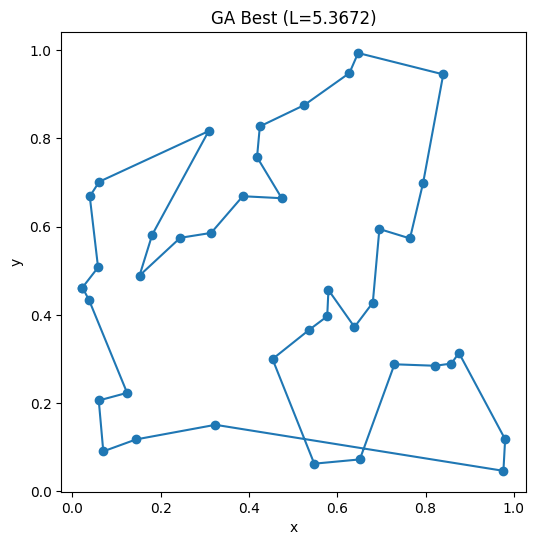

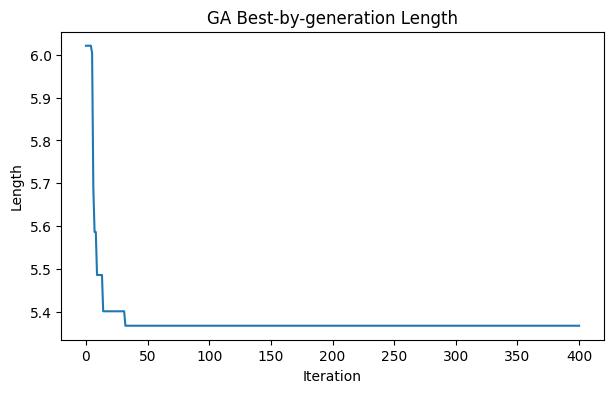

In [9]:
ga_cfg = GAConfig(pop_size=200, generations=400, tournament_k=5, crossover_rate=0.9,
                   mutation_rate=0.2, elite_size=5, seed=999, report_every=50)

ga_best_tour, ga_best_len, ga_hist = genetic_algorithm_tsp(cities, init_seed_tours=[nn_tour], cfg=ga_cfg)

print(f"GA best length: {ga_best_len:.4f}")
print(f"GA improvement vs NN: {(nn_len - ga_best_len) / nn_len * 100:.2f}%")

plot_tour(cities, ga_best_tour, title=f"GA Best (L={ga_best_len:.4f})")
plot_history(ga_hist, title="GA Best-by-generation Length", ylabel="Length")


# Part 6 — Data Collection, Visualization and Comparison

* Instrument the code to collect the data and visualize them, including but not limited to
  * SA:
    * Track histogram of ΔE values for: Accepted moves and Rejected moves
  * GA:
    * Population average fitness
  * Cross SA and GA:
    * Plot SA best-so-far curve
    * Plot GA best-by-generation curve
    * Normalize x-axis by total evaluations
    * The above is already provided in the skeleton code. **Use them and/or with additional instrumentation of the code to collect and/or plot more data** to answer the following questions:
      * Which algorithm converged faster?
      * Which showed more variability?
      * Did SA escape local minima? Evidence?
      * Did GA lose diversity? Evidence?
* You are encouraged to come up with your own visualization and compare these two methods more extensively.

NN: 6.0214 | SA: 5.0057 | GA: 5.3672
SA uphill accepted: 267 / 20000 moves
GA unique tour fraction: 1.000 -> 0.185
Total evaluations: SA=20001, GA=80200


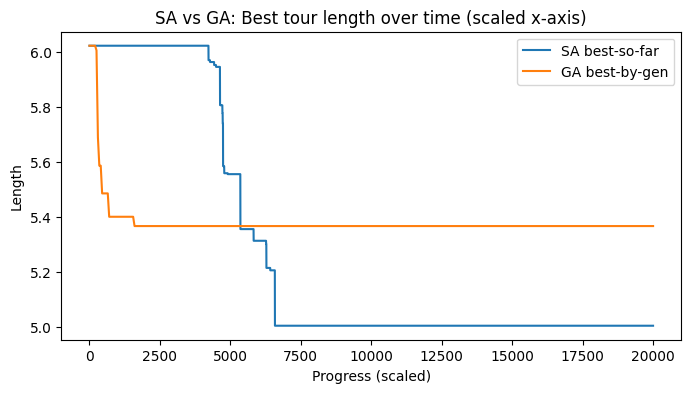

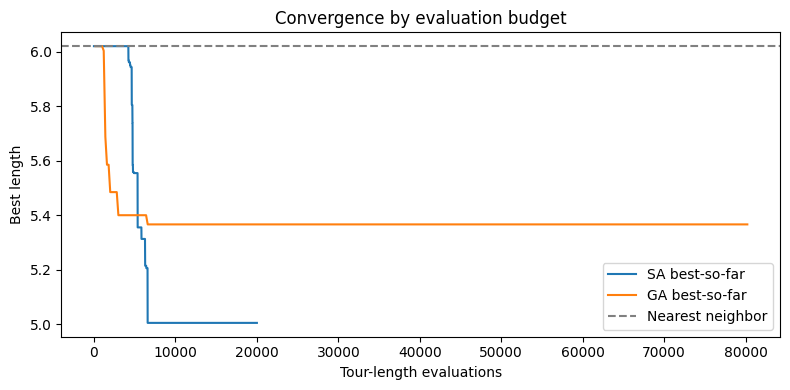

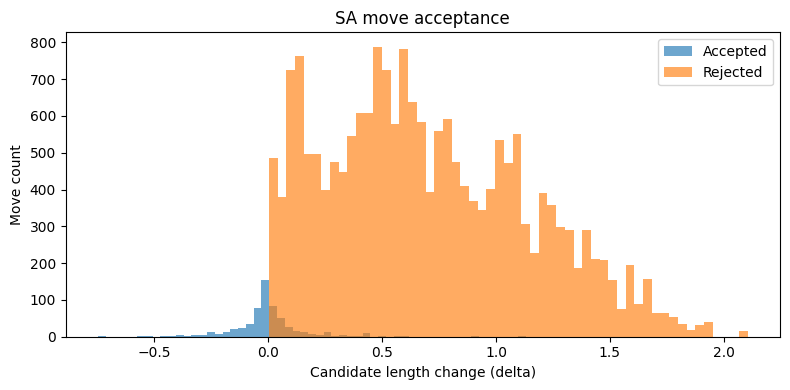

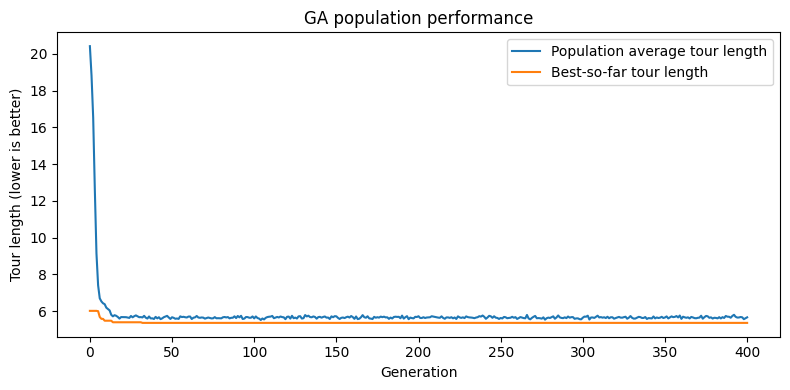

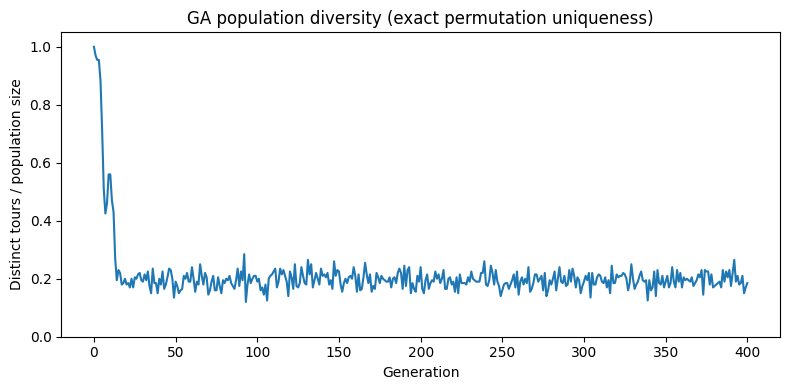

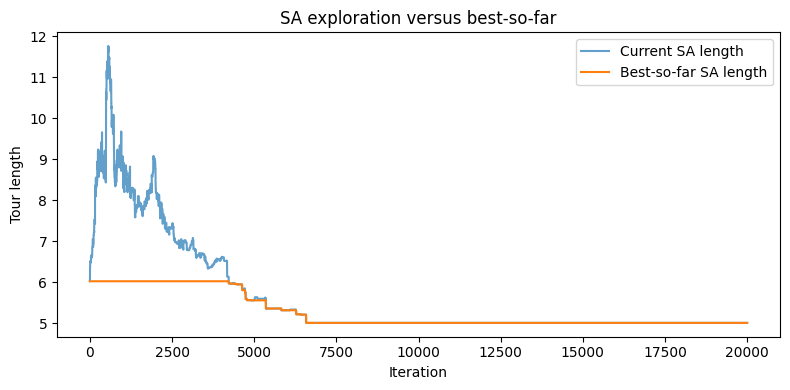

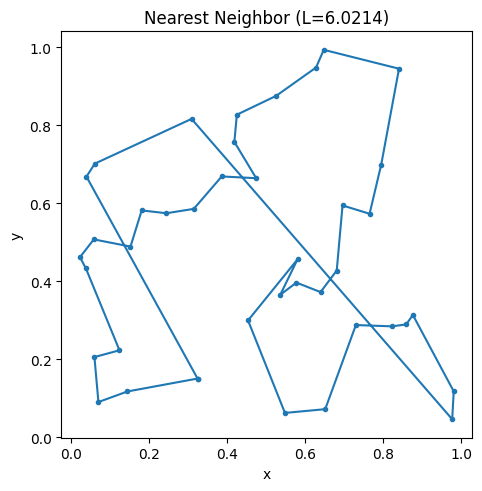

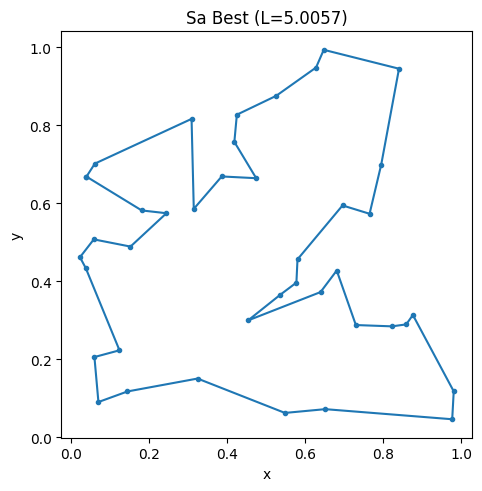

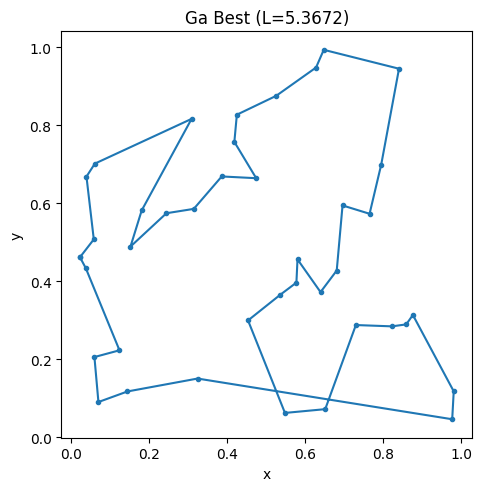


5-run comparison (both initialized with NN):
run | SA length | GA length
  1 |    5.0057 |    5.3672
  2 |    4.8339 |    5.9001
  3 |    4.8339 |    5.9215
  4 |    5.0247 |    5.1676
  5 |    5.0780 |    5.3245
SA mean/std: 4.9553 0.1139
GA mean/std: 5.5362 0.35


In [10]:
# Part 6: compare quality, evaluation budgets, acceptance and population diversity.
import os
import statistics
os.makedirs("figures", exist_ok=True)
sa_diag = simulated_annealing_tsp.diagnostics
ga_diag = genetic_algorithm_tsp.diagnostics
print(f"NN: {nn_len:.4f} | SA: {sa_best_len:.4f} | GA: {ga_best_len:.4f}")
print(f"SA uphill accepted: {sa_diag['uphill_accepted']} / {sa_cfg.iters} moves")
print(f"GA unique tour fraction: {ga_diag['unique_fractions'][0]:.3f} -> {ga_diag['unique_fractions'][-1]:.3f}")
print(f"Total evaluations: SA={sa_diag['evaluations']}, GA={ga_diag['evaluations']}")
plot_compare(sa_hist, ga_hist)  # The original skeleton's scaled comparison.

# Compare on ACTUAL tour-length evaluations, not iteration/generation counts.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(len(sa_hist)), sa_hist, label="SA best-so-far")
ax.plot([ga_cfg.pop_size*(i+1) for i in range(len(ga_hist))], ga_hist,
        label="GA best-so-far")
ax.axhline(nn_len, linestyle="--", color="gray", label="Nearest neighbor")
ax.set(xlabel="Tour-length evaluations", ylabel="Best length", title="Convergence by evaluation budget")
ax.legend(); fig.tight_layout(); fig.savefig("figures/evaluation_convergence.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sa_diag['accepted_deltas'], bins=55, alpha=0.65, label="Accepted")
ax.hist(sa_diag['rejected_deltas'], bins=55, alpha=0.65, label="Rejected")
ax.set(xlabel="Candidate length change (delta)", ylabel="Move count", title="SA move acceptance")
ax.legend(); fig.tight_layout(); fig.savefig("figures/sa_delta_histogram.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ga_diag['avg_lengths'], label="Population average tour length")
ax.plot(ga_hist, label="Best-so-far tour length")
ax.set(xlabel="Generation", ylabel="Tour length (lower is better)", title="GA population performance")
ax.legend(); fig.tight_layout(); fig.savefig("figures/ga_population_average.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ga_diag['unique_fractions'])
ax.set(xlabel="Generation", ylabel="Distinct tours / population size", ylim=(0, 1.05),
       title="GA population diversity (exact permutation uniqueness)")
fig.tight_layout(); fig.savefig("figures/ga_diversity.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sa_diag['current_history'], label="Current SA length", alpha=0.7)
ax.plot(sa_hist, label="Best-so-far SA length")
ax.set(xlabel="Iteration", ylabel="Tour length", title="SA exploration versus best-so-far")
ax.legend(); fig.tight_layout(); fig.savefig("figures/sa_current_vs_best.png", dpi=180); plt.show()

# Save the three tour figures to disk for technical reporting.
for tour, label, value in [(nn_tour,"nearest_neighbor",nn_len),
                           (sa_best_tour,"sa_best",sa_best_len),
                           (ga_best_tour,"ga_best",ga_best_len)]:
    xs = [cities[i][0] for i in tour] + [cities[tour[0]][0]]
    ys = [cities[i][1] for i in tour] + [cities[tour[0]][1]]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot(xs, ys, marker="o", markersize=3)
    ax.set(xlabel="x", ylabel="y", title=f"{label.replace('_',' ').title()} (L={value:.4f})")
    ax.set_aspect("equal", adjustable="box")
    fig.tight_layout(); fig.savefig(f"figures/{label}.png", dpi=180); plt.show()

# Five runs with independent algorithm seeds quantify stochastic variability.
trial_rows = []
for trial in range(5):
    sc = SAConfig(iters=sa_cfg.iters, t0=sa_cfg.t0, alpha=sa_cfg.alpha,
                  seed=sa_cfg.seed+trial, report_every=0)
    gc = GAConfig(pop_size=ga_cfg.pop_size, generations=ga_cfg.generations,
                  tournament_k=ga_cfg.tournament_k, crossover_rate=ga_cfg.crossover_rate,
                  mutation_rate=ga_cfg.mutation_rate, elite_size=ga_cfg.elite_size,
                  seed=ga_cfg.seed+trial, report_every=0)
    _, sl, _ = simulated_annealing_tsp(cities, nn_tour, sc)
    _, gl, _ = genetic_algorithm_tsp(cities, [nn_tour], gc)
    trial_rows.append((trial+1, sl, gl))
print("\n5-run comparison (both initialized with NN):")
print("run | SA length | GA length")
for i, sl, gl in trial_rows:
    print(f"{i:3d} | {sl:9.4f} | {gl:9.4f}")
print("SA mean/std:", round(statistics.mean(r[1] for r in trial_rows),4),
      round(statistics.stdev(r[1] for r in trial_rows),4))
print("GA mean/std:", round(statistics.mean(r[2] for r in trial_rows),4),
      round(statistics.stdev(r[2] for r in trial_rows),4))

import json
with open("experiment_results.json", "w") as f:
    json.dump(dict(nn_length=nn_len, sa_length=sa_best_len, ga_length=ga_best_len,
      sa_config=vars(sa_cfg), ga_config=vars(ga_cfg),
      sa_accepted=len(sa_diag['accepted_deltas']), sa_rejected=len(sa_diag['rejected_deltas']),
      sa_uphill_accepted=sa_diag['uphill_accepted'],
      ga_unique_start=ga_diag['unique_fractions'][0],
      ga_unique_end=ga_diag['unique_fractions'][-1],
      ga_avg_start=ga_diag['avg_lengths'][0], ga_avg_end=ga_diag['avg_lengths'][-1],
      trials=trial_rows, sa_history=sa_hist, ga_history=ga_hist),f,indent=2)


### Part 6 interpretation

See the accompanying technical report for numerical analysis of convergence speed, variation over five seeds, uphill SA steps, and population diversity. The GA evaluation curve counts every individual in each generation, whereas SA counts every candidate. Exact permutation uniqueness is a limited diversity indicator because reversals and rotations describe equivalent TSP cycles.


## Example of how to check your work

In [11]:
def grade_check(nn_len: float, method_len: float, min_improvement_pct: float = 10.0, label: str = "Method") -> None:
    improvement = (nn_len - method_len) / nn_len * 100.0
    print(f"{label} length: {method_len:.4f} | Improvement vs NN: {improvement:.2f}%")
    assert improvement >= min_improvement_pct, (
        f"{label} improvement {improvement:.2f}% is below required {min_improvement_pct:.2f}%"
    )
    print(f"✅ {label} passed improvement threshold!")


# Part 7: Optional Task

The optional extra work will be considered for extra credit.

- Try different crossover and/or mutation operations in GA and see if you can improve the performance.

- If you identify other interesting analytics of intermediate data that shows how the algorithms are performing, you can carry out the experiements in this section.

- Document your effort in this section **and** the technical report mentioned above in the Deliverables.

